In [ ]:
# Deep Learning Algorithms & Optimization Techniques
# Dataset: Breast Cancer Wisconsin - built into sklearn, no download needed
#
# Needs: pip install tensorflow
#
# This builds a plain feedforward deep neural network (not CNN/RNN - those
# are their own scripts, since they need different data shapes) and compares
# how different OPTIMIZERS affect training - that's the actual algorithm
# behind "how a neural network learns."
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
tf.random.set_seed(42)
np.random.seed(42)

cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
# ---- 1. Build a simple feedforward (dense) deep neural network ----
# "deep" just means more than one hidden layer - this one has two
def build_model():
    model = keras.Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")   # binary output
    ])
    return model

model = build_model()
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# ---- 2. Compile with a chosen optimizer ----
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# ---- 3. Train ----
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=0
)



Test accuracy (Adam): 0.9649


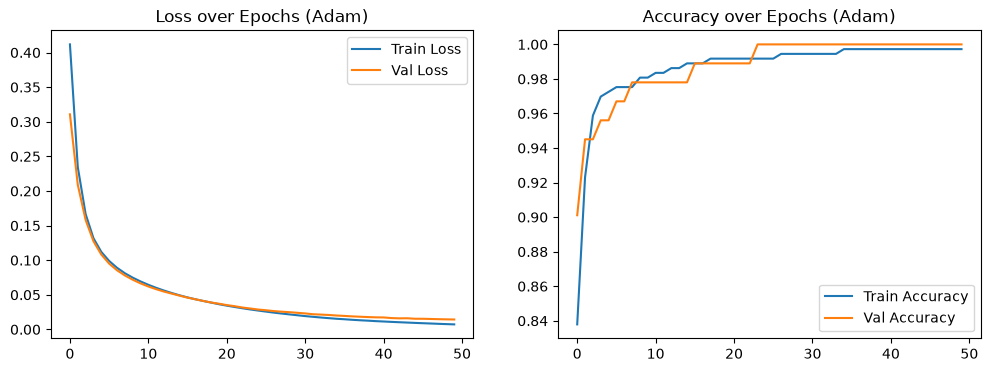

In [6]:
# ---- 4. Evaluate ----
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"\nTest accuracy (Adam): {test_acc:.4f}")

# ---- 5. Plot training history ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss over Epochs (Adam)")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Accuracy over Epochs (Adam)")
axes[1].legend()
plt.show()



In [7]:
# ============================================================
# OPTIMIZATION TECHNIQUES - compare how different optimizers learn
# ============================================================
# All of these are variations on gradient descent - the core idea of
# "nudge weights in the direction that reduces loss" - but they differ in
# HOW they use past gradients to decide step size and direction.

optimizers_to_try = {
    "SGD (plain)": keras.optimizers.SGD(learning_rate=0.01),
    "SGD + Momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": keras.optimizers.Adam(learning_rate=0.001),
}

histories = {}

for name, opt in optimizers_to_try.items():
    tf.random.set_seed(42)   # reset seed so each model starts from the same point
    m = build_model()
    m.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    h = m.fit(X_train_scaled, y_train, validation_split=0.2,
              epochs=50, batch_size=16, verbose=0)
    histories[name] = h.history
    test_loss, test_acc = m.evaluate(X_test_scaled, y_test, verbose=0)
    print(f"{name:20s}  Test Accuracy: {test_acc:.4f}")


SGD (plain)           Test Accuracy: 0.9649
SGD + Momentum        Test Accuracy: 0.9649
RMSprop               Test Accuracy: 0.9561
Adam                  Test Accuracy: 0.9561


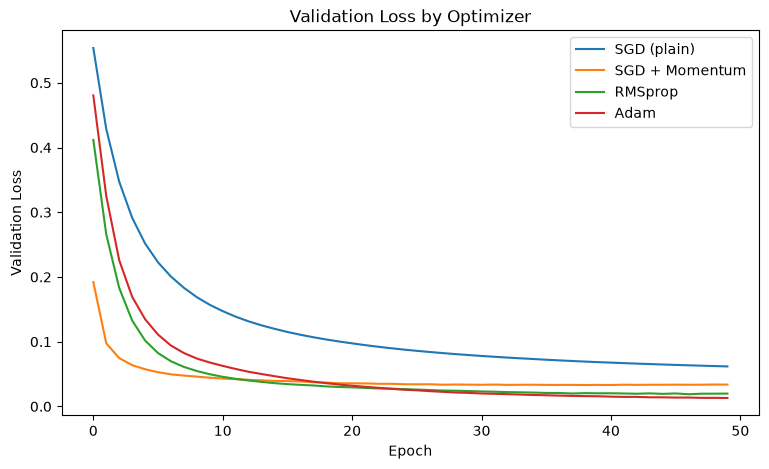

In [8]:
# ---- 6. Plot validation loss for every optimizer, side by side ----
plt.figure(figsize=(9, 5))
for name, hist in histories.items():
    plt.plot(hist["val_loss"], label=name)
plt.title("Validation Loss by Optimizer")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.show()

# plain SGD is usually the slowest to converge; momentum speeds it up;
# RMSprop/Adam (which adapt the learning rate per-parameter) usually
# converge fastest and most smoothly on problems like this

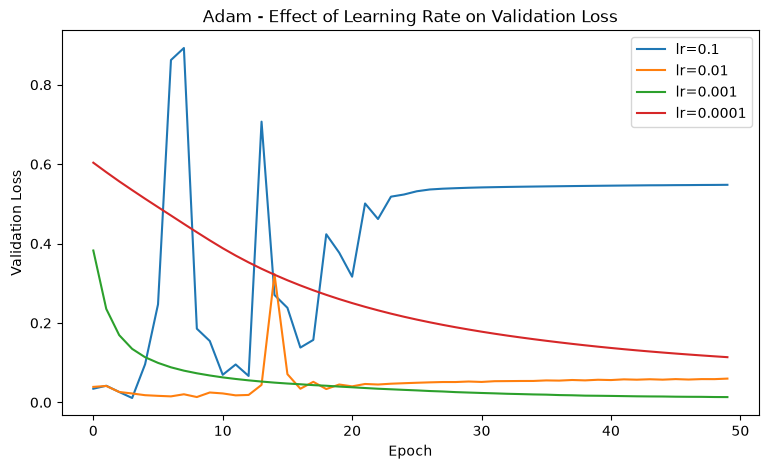

In [9]:
# ---- 7. Effect of learning rate on Adam specifically ----
learning_rates = [0.1, 0.01, 0.001, 0.0001]
lr_histories = {}

for lr in learning_rates:
    tf.random.set_seed(42)
    m = build_model()
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="binary_crossentropy", metrics=["accuracy"])
    h = m.fit(X_train_scaled, y_train, validation_split=0.2,
              epochs=50, batch_size=16, verbose=0)
    lr_histories[f"lr={lr}"] = h.history

plt.figure(figsize=(9, 5))
for name, hist in lr_histories.items():
    plt.plot(hist["val_loss"], label=name)
plt.title("Adam - Effect of Learning Rate on Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.show()

# too high -> loss jumps around / diverges
# too low -> loss decreases very slowly, barely moves in 50 epochs